# 머신러닝 심화 1일차 과제 — Mean Shift & DBSCAN 군집화 (load_iris)

- **작성자**: 조태희
- **과정**: OZ 코딩 스쿨 AI 헬스케어 부트캠프 · 머신러닝 심화 1일차 (군집화)
- **과제 안내**: "sklearn.datasets 의 load_iris 데이터를 사용하여 Mean Shift, DBSCAN 군집화 실습을 진행해주세요. (실습파일은 load_wine 을 썼지만 과제에서는 load_iris 로 변경해서 적용)"

## 🎯 학습 목표
1. 거리 기반 군집화에서 **스케일링(표준화)** 이 왜 필요한지 설명할 수 있습니다.
2. **Mean Shift** 의 `bandwidth`(탐색 반경)가 군집 수를 어떻게 바꾸는지 실험으로 확인합니다.
3. **DBSCAN** 의 `eps`, `min_samples`를 k-거리 그래프로 정하고, 노이즈(라벨 -1)를 해석할 수 있습니다.
4. 군집 결과를 실제 품종과 비교(**교차표, ARI**)하고, **실루엣 점수**로 군집 품질을 평가합니다.

> 💡 **군집화(clustering)** 는 정답(라벨) 없이 비슷한 데이터끼리 묶는 **비지도 학습**입니다. 이번 과제에서 붓꽃 품종(정답)은 학습에는 쓰지 않고, **결과를 채점할 때만** 사용합니다.

## 0. 환경 준비
그래프의 한글이 □□□처럼 깨지지 않도록 한글 글꼴 패키지를 설치하고, 필요한 라이브러리를 불러옵니다.

In [1]:
# 그래프 한글 깨짐을 막아 주는 패키지 설치 (Colab에서 실행, -q: 설치 로그를 짧게)
!pip install -q koreanize-matplotlib

In [2]:
# 불러오기만 하면 matplotlib의 기본 글꼴이 한글 글꼴(나눔고딕)로 자동 설정됩니다
import koreanize_matplotlib

In [3]:
import numpy as np                 # 숫자 배열 계산 라이브러리
import pandas as pd                # 표(DataFrame) 형태의 데이터를 다루는 라이브러리
import matplotlib as mpl           # 그래프 전체 설정(색 순서 등)용
import matplotlib.pyplot as plt    # 그래프 그리기 라이브러리

from sklearn.datasets import load_iris                        # 붓꽃(iris) 예제 데이터
from sklearn.preprocessing import StandardScaler              # 표준화 도구 (평균 0, 표준편차 1로 맞춤)
from sklearn.cluster import MeanShift, estimate_bandwidth     # Mean Shift 군집화 + bandwidth 추정 함수
from sklearn.cluster import DBSCAN                            # DBSCAN 군집화
from sklearn.neighbors import NearestNeighbors                # 가장 가까운 이웃 찾기 (k-거리 그래프용)
from sklearn.decomposition import PCA                         # 주성분 분석 (4차원 → 2차원 시각화용)
from sklearn.metrics import adjusted_rand_score, silhouette_score  # 군집 평가 지표 (ARI, 실루엣)

RANDOM_STATE = 42                       # 재현성(다시 실행해도 같은 결과)을 위한 랜덤 시드
pd.set_option("display.precision", 4)   # 표의 소수점은 4자리까지 표시

# 그래프 공통 스타일 ------------------------------------------------------------
# 색약이 있어도 구분되도록 검증된 순서의 색 (앞의 3개: 파랑·주황·청록)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # 그룹 순서대로 쓸 색 목록
MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]  # 색만으로 구분하지 않도록 점 모양도 함께 바꿈
NOISE_COLOR = "#898781"                             # 노이즈 점에 쓸 회색
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=COLORS)  # 기본 색 순서를 위 색상으로 지정
mpl.rcParams["axes.spines.top"] = False     # 그래프 위쪽 테두리 숨기기
mpl.rcParams["axes.spines.right"] = False   # 그래프 오른쪽 테두리 숨기기
mpl.rcParams["axes.grid"] = True            # 격자 표시
mpl.rcParams["grid.color"] = "#e1e0d9"      # 격자는 아주 연한 회색 (데이터보다 눈에 덜 띄게)
mpl.rcParams["grid.linewidth"] = 0.8        # 격자 선은 가늘게
mpl.rcParams["axes.axisbelow"] = True       # 격자를 막대·점 아래에 그리기 (데이터를 가리지 않게)
print("준비 완료!")                           # 설정이 끝났다는 확인 메시지

준비 완료!


## 1. 데이터 불러오기 & 살펴보기
`load_iris()`에는 붓꽃 150송이의 **꽃받침(sepal)·꽃잎(petal)의 길이와 너비**(4개 피처, 단위 cm)와 **품종**(setosa, versicolor, virginica) 정보가 들어 있습니다. 코드를 쓰기 전에 먼저 **데이터의 생김새**(샘플 몇 줄, 컬럼, 타입)부터 확인합니다.

In [4]:
iris = load_iris()  # 붓꽃 데이터 불러오기 (딕셔너리처럼 꺼내 쓰는 Bunch 객체)

feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]  # 꽃받침 길이·너비, 꽃잎 길이·너비 (cm)
df = pd.DataFrame(iris.data, columns=feature_cols)  # 측정값 4개를 표(DataFrame)로 만들기
df["species"] = iris.target_names[iris.target]      # 정답 번호(0,1,2)를 품종 이름으로 바꿔 'species' 컬럼에 저장

print("데이터 크기 (행, 열):", df.shape)  # (샘플 수, 컬럼 수)
df.head()                                 # 앞 5줄 미리보기

데이터 크기 (행, 열): (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
df.info()  # 컬럼별 데이터 타입과 결측치(빈 값) 여부 확인 → Non-Null 개수가 150이면 빈 값 없음

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [6]:
print(df["species"].value_counts())  # 품종별 개수 → 균형이 맞는지 확인
df.describe().round(2)               # 숫자 컬럼의 평균(mean)·표준편차(std)·최솟값·최댓값 등 요약 통계

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


**관찰 포인트**
- 품종은 50송이씩 균형이 맞고, `info()`에서 모든 컬럼의 Non-Null 개수가 150이므로 **결측치(빈 값)가 없습니다.**
- `describe()`의 표준편차(std)를 보면 피처마다 값이 퍼진 정도가 다릅니다. 꽃잎 길이(petal_length)는 1.77인데 꽃받침 너비(sepal_width)는 0.44로 약 4배 차이가 납니다. 이 차이가 뒤에서 **스케일링이 필요한 이유**가 됩니다.

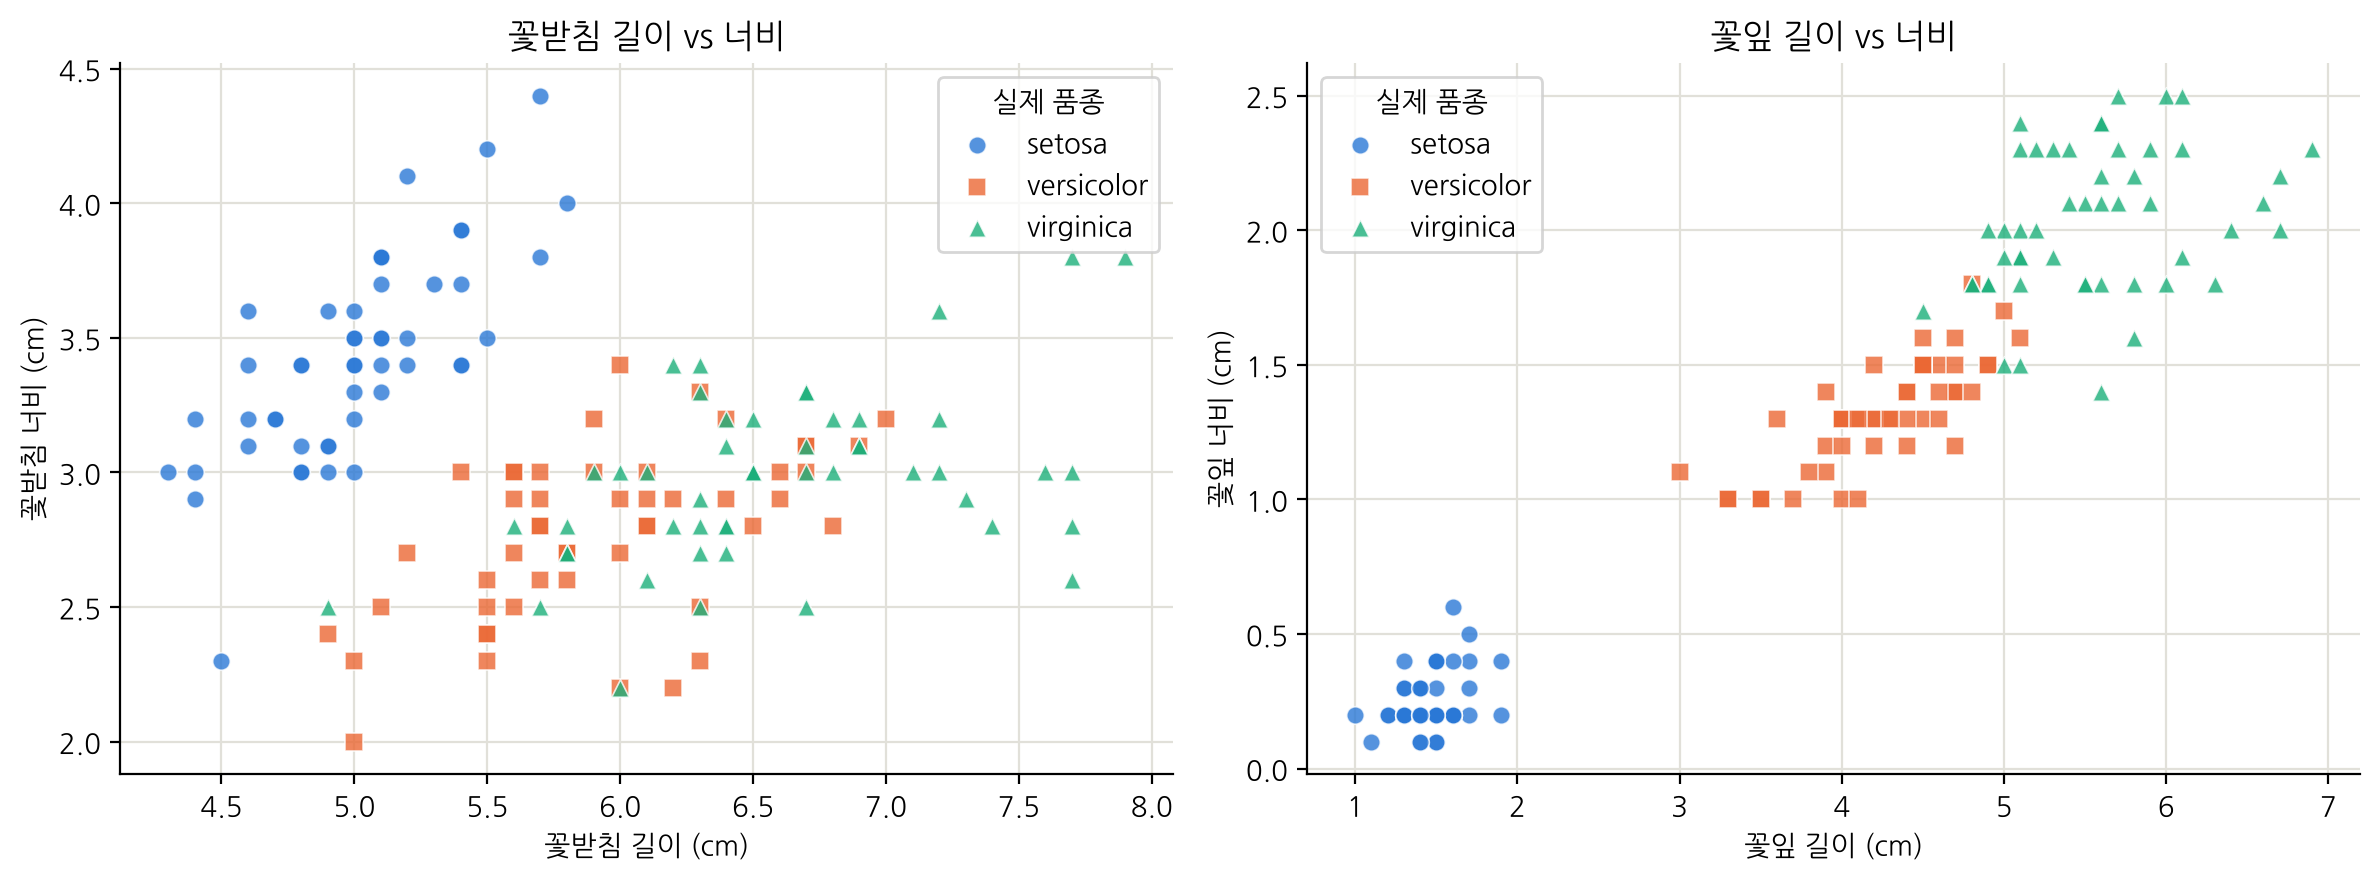

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))  # 1행 2열 그래프 영역 만들기
for i, name in enumerate(iris.target_names):       # 품종 번호(i)와 이름(name)을 하나씩 꺼내 반복
    part = df[df["species"] == name]               # 해당 품종의 행만 골라내기
    style = dict(color=COLORS[i], marker=MARKERS[i], s=40, alpha=0.8,      # 점 색·모양·크기(s)·투명도(alpha)
                 edgecolors="white", linewidths=0.6, label=name)  # 품종마다 다른 색·모양 (흰 테두리로 겹친 점 구분)
    axes[0].scatter(part["sepal_length"], part["sepal_width"], **style)  # 왼쪽: 꽃받침 길이 vs 너비
    axes[1].scatter(part["petal_length"], part["petal_width"], **style)  # 오른쪽: 꽃잎 길이 vs 너비
axes[0].set(title="꽃받침 길이 vs 너비", xlabel="꽃받침 길이 (cm)", ylabel="꽃받침 너비 (cm)")  # 왼쪽 제목·축 이름
axes[1].set(title="꽃잎 길이 vs 너비", xlabel="꽃잎 길이 (cm)", ylabel="꽃잎 너비 (cm)")        # 오른쪽 제목·축 이름
for ax in axes:                          # 두 그래프 모두
    ax.legend(title="실제 품종")          # 범례 표시
plt.tight_layout()                       # 그래프끼리 겹치지 않게 간격 자동 조정
plt.show()                               # 화면에 출력

→ **setosa는 다른 두 품종과 확실히 떨어져** 있지만, **versicolor와 virginica는 경계가 맞닿아 일부 겹칩니다.** 정답 없이 '모여 있는 정도(밀도)'만 보는 군집화가 이 둘을 나눌 수 있을지가 이번 과제의 관전 포인트입니다.

## 2. 스케일링 (StandardScaler)

Mean Shift와 DBSCAN은 둘 다 **"가까우면 같은 군집"** 이라는 **거리(유클리드 거리)** 기반 알고리즘입니다.

🍎 **비유**: 친구들 사이의 '거리'를 키(cm)와 시력으로 잰다고 해 봅시다. 키는 10~20씩 차이 나는 게 보통이지만 시력은 0.5만 달라도 큰 차이입니다. 그런데 숫자를 그대로 빼서 거리를 재면 키 차이가 거리를 거의 다 차지해 버리죠. 이처럼 피처마다 값이 퍼진 정도가 다르면 **많이 퍼진 피처가 거리 계산을 독차지**합니다.

그래서 `StandardScaler`로 모든 피처를 **평균 0, 표준편차 1**로 맞춰(표준화, standardization) 네 피처가 거리 계산에 공평하게 참여하게 합니다.
- 공식: `z = (x − 평균) / 표준편차` → "평균에서 표준편차 몇 개만큼 떨어져 있나"로 바꾸는 것입니다.
- 군집화는 train/test를 나누지 않으므로 전체 데이터로 `fit`해도 괜찮습니다. (지도학습에서는 **훈련 세트로만 fit** 해야 합니다!)

In [8]:
X = df[feature_cols].values  # 군집화에 쓸 입력: 측정값 4개만 numpy 배열로 꺼내기 (정답 species는 넣지 않음!)
y_true = iris.target         # 정답 품종 번호(0,1,2) → 학습에는 쓰지 않고 나중에 채점할 때만 사용

scaler = StandardScaler()           # 표준화 도구 만들기
X_scaled = scaler.fit_transform(X)  # 피처별 평균·표준편차를 계산(fit)하고 바로 변환(transform)

# (+ 0.0은 -0.0 같은 표시를 0.0으로 정리하는 작은 요령입니다)
# StandardScaler는 표준편차를 ddof=0 방식으로 계산하므로 여기서도 np.std(ddof=0 기본값)로 확인합니다
print("스케일링 전 평균    :", X.mean(axis=0).round(2))               # 피처별 평균 (axis=0: 열 방향)
print("스케일링 전 표준편차:", X.std(axis=0).round(2))                # 피처별 표준편차 → 제각각
print("스케일링 후 평균    :", X_scaled.mean(axis=0).round(2) + 0.0)  # 모두 0
print("스케일링 후 표준편차:", X_scaled.std(axis=0).round(2))         # 모두 1

스케일링 전 평균    : [5.84 3.06 3.76 1.2 ]
스케일링 전 표준편차: [0.83 0.43 1.76 0.76]
스케일링 후 평균    : [0. 0. 0. 0.]
스케일링 후 표준편차: [1. 1. 1. 1.]


## PART 1. Mean Shift

⛰️ **비유**: 안개 낀 산에 사람들이 흩어져 있습니다. 각자 **손전등이 비추는 반경(bandwidth)** 안에서 사람이 가장 많이 모인 쪽(평균 위치)으로 한 걸음씩 옮깁니다. 이걸 반복하면 모두 근처의 **봉우리(밀도가 가장 높은 곳)** 에 도착하고, **같은 봉우리에 도착한 사람끼리 하나의 군집**이 됩니다.

- **정확한 정의**: 각 점에서 반경 `bandwidth` 안에 있는 점들의 **평균(mean) 위치로 이동(shift)** 하는 과정을 더 이상 움직이지 않을 때까지 반복해, 밀도의 최고점(mode)을 찾습니다. 서로 가까운 봉우리는 하나로 합치고, 마지막에 각 점을 가장 가까운 봉우리(군집 중심)에 배정합니다.
- 군집 수를 미리 정하지 않아도 되지만, **bandwidth가 작으면 봉우리가 많이(군집 多), 크면 적게(군집 少)** 잡힙니다.

### 1-1. bandwidth 추정하기
bandwidth를 감으로 정하기 어려우니 `estimate_bandwidth()`로 데이터에 맞는 값을 추정합니다.
- `quantile=0.3`(기본값)이면 각 점마다 **자기 자신을 포함해 가장 가까운 150 × 0.3 = 45개 점** 중 가장 먼 점까지의 거리를 재고, 그 거리를 150개 점 전체에 대해 **평균** 낸 값을 돌려줍니다.
- 즉 quantile이 작을수록 → 더 가까운 이웃까지만 보므로 → bandwidth가 작아집니다.

In [9]:
bandwidth = estimate_bandwidth(X_scaled, quantile=0.3, random_state=RANDOM_STATE)  # bandwidth 추정 (quantile 기본값 0.3)
print(f"추정된 bandwidth: {bandwidth:.4f}")                                       # 소수점 4자리로 출력

추정된 bandwidth: 1.6025


In [10]:
# 🔍 estimate_bandwidth가 속으로 하는 일을 직접 따라 해 보기
n_neighbors = int(len(X_scaled) * 0.3)                        # 150 × 0.3 = 45개 이웃 (자기 자신 포함)
nn_bw = NearestNeighbors(n_neighbors=n_neighbors).fit(X_scaled)  # '가장 가까운 이웃 찾기' 도구를 데이터에 맞추기
dist_bw, _ = nn_bw.kneighbors(X_scaled)                       # 각 점에서 가까운 45개 점까지의 거리 (가까운 순, 첫 칸은 자기 자신=0)
manual_bandwidth = dist_bw[:, -1].mean()                      # 각 점의 '45번째로 가까운 점까지 거리'(마지막 칸)를 평균

print(f"이웃 수: {n_neighbors}개")                              # 사용한 이웃 수 출력
print(f"직접 계산한 bandwidth: {manual_bandwidth:.4f}")         # 직접 계산한 값 (소수 4자리)
print("estimate_bandwidth 결과와 같은가?", np.isclose(bandwidth, manual_bandwidth))  # True면 원리를 정확히 이해한 것

이웃 수: 45개
직접 계산한 bandwidth: 1.6025
estimate_bandwidth 결과와 같은가? True


### 1-2. Mean Shift 학습하기

In [11]:
meanshift = MeanShift(bandwidth=bandwidth)   # 추정한 bandwidth로 Mean Shift 모델 만들기
ms_labels = meanshift.fit_predict(X_scaled)  # 학습(봉우리 찾기) + 각 점의 군집 번호 받기

n_clusters_ms = len(np.unique(ms_labels))    # 서로 다른 군집 번호의 개수 = 군집 수
print(f"Mean Shift가 찾은 군집 수: {n_clusters_ms}개")  # 군집 수 출력
print("\n군집별 데이터 수:")                          # 소제목 출력 (\n: 한 줄 띄우기)
print(pd.Series(ms_labels, name="군집").value_counts().sort_index())  # 군집 번호별 개수 (번호 순 정렬)

Mean Shift가 찾은 군집 수: 2개

군집별 데이터 수:
군집
0    100
1     50
Name: count, dtype: int64


In [12]:
# 군집 중심(봉우리 위치)은 표준화된 값이라 해석이 어려우니, 원래 단위(cm)로 되돌려서 봅니다
centers_cm = pd.DataFrame(scaler.inverse_transform(meanshift.cluster_centers_), columns=feature_cols)  # 표준화를 거꾸로 적용
centers_cm.index.name = "군집"  # 행 이름 = 군집 번호
centers_cm.round(2)             # 소수 둘째 자리까지 표시

,sepal_length,sepal_width,petal_length,petal_width
군집,,,,
0,6.26,2.92,4.91,1.70
1,4.97,3.39,1.47,0.25


### 1-3. 실제 품종과 비교하기
- **교차표 `pd.crosstab(실제, 군집)`**: 실제 품종별로 어느 군집에 몇 송이가 들어갔는지 세는 표입니다.
- **ARI (Adjusted Rand Index, 조정 랜드 지수)**: 두 묶음 방식이 얼마나 일치하는지 나타냅니다. 무작위로 묶으면 0 근처, 완벽히 일치하면 1입니다(무작위보다 나쁘면 음수도 가능). 군집 번호(0, 1, 2)가 품종 번호와 달라도 **"같이 묶였는가"** 만 보고 비교하므로 번호를 맞출 필요가 없습니다. → **정답이 있어야 계산 가능**
- **실루엣 점수 (Silhouette score)**: 각 점이 **자기 군집과는 얼마나 가깝고, 가장 가까운 다른 군집과는 얼마나 먼지**를 -1 ~ 1로 나타낸 값의 평균입니다. 1에 가까울수록 군집이 잘 뭉치고 서로 잘 떨어져 있다는 뜻입니다. → **정답 없이 계산 가능**

In [13]:
species_names = pd.Series(iris.target_names[y_true], name="실제 품종")         # 정답 번호 → 품종 이름 (교차표 행 이름용)
display(pd.crosstab(species_names, pd.Series(ms_labels, name="Mean Shift 군집")))  # 품종 × 군집 교차표

ms_ari = adjusted_rand_score(y_true, ms_labels)  # 정답과 군집 결과의 일치도 (정답 사용)
ms_sil = silhouette_score(X_scaled, ms_labels)   # 군집이 얼마나 잘 뭉치고 떨어져 있는지 (정답 사용 안 함)
print(f"ARI: {ms_ari:.4f}")          # ARI 출력 (소수 4자리)
print(f"실루엣 점수: {ms_sil:.4f}")   # 실루엣 점수 출력 (소수 4자리)

Mean Shift 군집,0,1
실제 품종,,
setosa,0,50
versicolor,50,0
virginica,50,0


ARI: 0.5681
실루엣 점수: 0.5818


→ Mean Shift는 **군집 2개**를 찾았습니다. 교차표를 보면 **setosa 50송이는 모두 한 군집(1번)** 에 모였고, **versicolor 50송이와 virginica 50송이는 다른 한 군집(0번)으로 합쳐졌습니다.** 앞의 산점도에서 본 것처럼 두 품종 사이에 밀도가 낮은 '골짜기'가 뚜렷하지 않아 하나의 봉우리로 잡힌 것입니다.
- ARI **0.5681**: setosa는 완벽히 분리했지만, versicolor와 virginica를 구분하지 못한 만큼 1보다 낮습니다.
- 실루엣 점수 **0.5818**: 두 덩어리가 서로 꽤 잘 떨어져 있다는 뜻입니다.
- 군집 중심(cm)을 보면 1번 군집은 꽃잎 길이·너비가 작은 쪽이라 setosa의 특징과 맞습니다.

### 1-4. bandwidth 바꿔 보기 (quantile 0.1 / 0.2 / 0.3)
quantile을 바꾸면 bandwidth가 바뀝니다. bandwidth에 따라 군집 수와 점수가 어떻게 달라지는지 표로 정리합니다.

In [14]:
ms_results = []                    # 실험 결과를 한 줄씩 담을 리스트
for q in [0.1, 0.2, 0.3]:          # quantile을 바꿔 가며 반복
    bw = estimate_bandwidth(X_scaled, quantile=q, random_state=RANDOM_STATE)  # 해당 quantile의 bandwidth 추정
    labels = MeanShift(bandwidth=bw).fit_predict(X_scaled)                    # 그 bandwidth로 군집화
    n_clu = len(np.unique(labels))                                            # 군집 수
    sil = silhouette_score(X_scaled, labels) if n_clu >= 2 else np.nan        # 실루엣은 군집이 2개 이상일 때만 계산 가능
    ms_results.append({                                                       # 결과 한 줄을 딕셔너리로 추가
        "quantile": q,                                                        # 사용한 quantile
        "bandwidth": round(bw, 4),                                            # 추정된 bandwidth (소수 4자리)
        "군집 수": n_clu,                                                      # 찾은 군집 수
        "군집별 크기": np.bincount(labels).tolist(),                           # 군집 번호(0,1,2,...)별 데이터 수
        "ARI": round(adjusted_rand_score(y_true, labels), 4),                 # 정답과의 일치도
        "실루엣": round(sil, 4),                                               # 군집 품질 (정답 없이 계산)
    })
ms_table = pd.DataFrame(ms_results)  # 리스트를 표로 변환
ms_table                             # 표 출력 (셀 마지막 줄에 변수 이름만 쓰면 화면에 보여 줌)

,quantile,bandwidth,군집 수,군집별 크기,ARI,실루엣
0,0.1,0.8512,7,"[40, 49, 35, 18, 2, 1, 5]",0.5956,0.3584
1,0.2,1.2070,4,"[88, 49, 8, 5]",0.5362,0.3585
2,0.3,1.6025,2,"[100, 50]",0.5681,0.5818


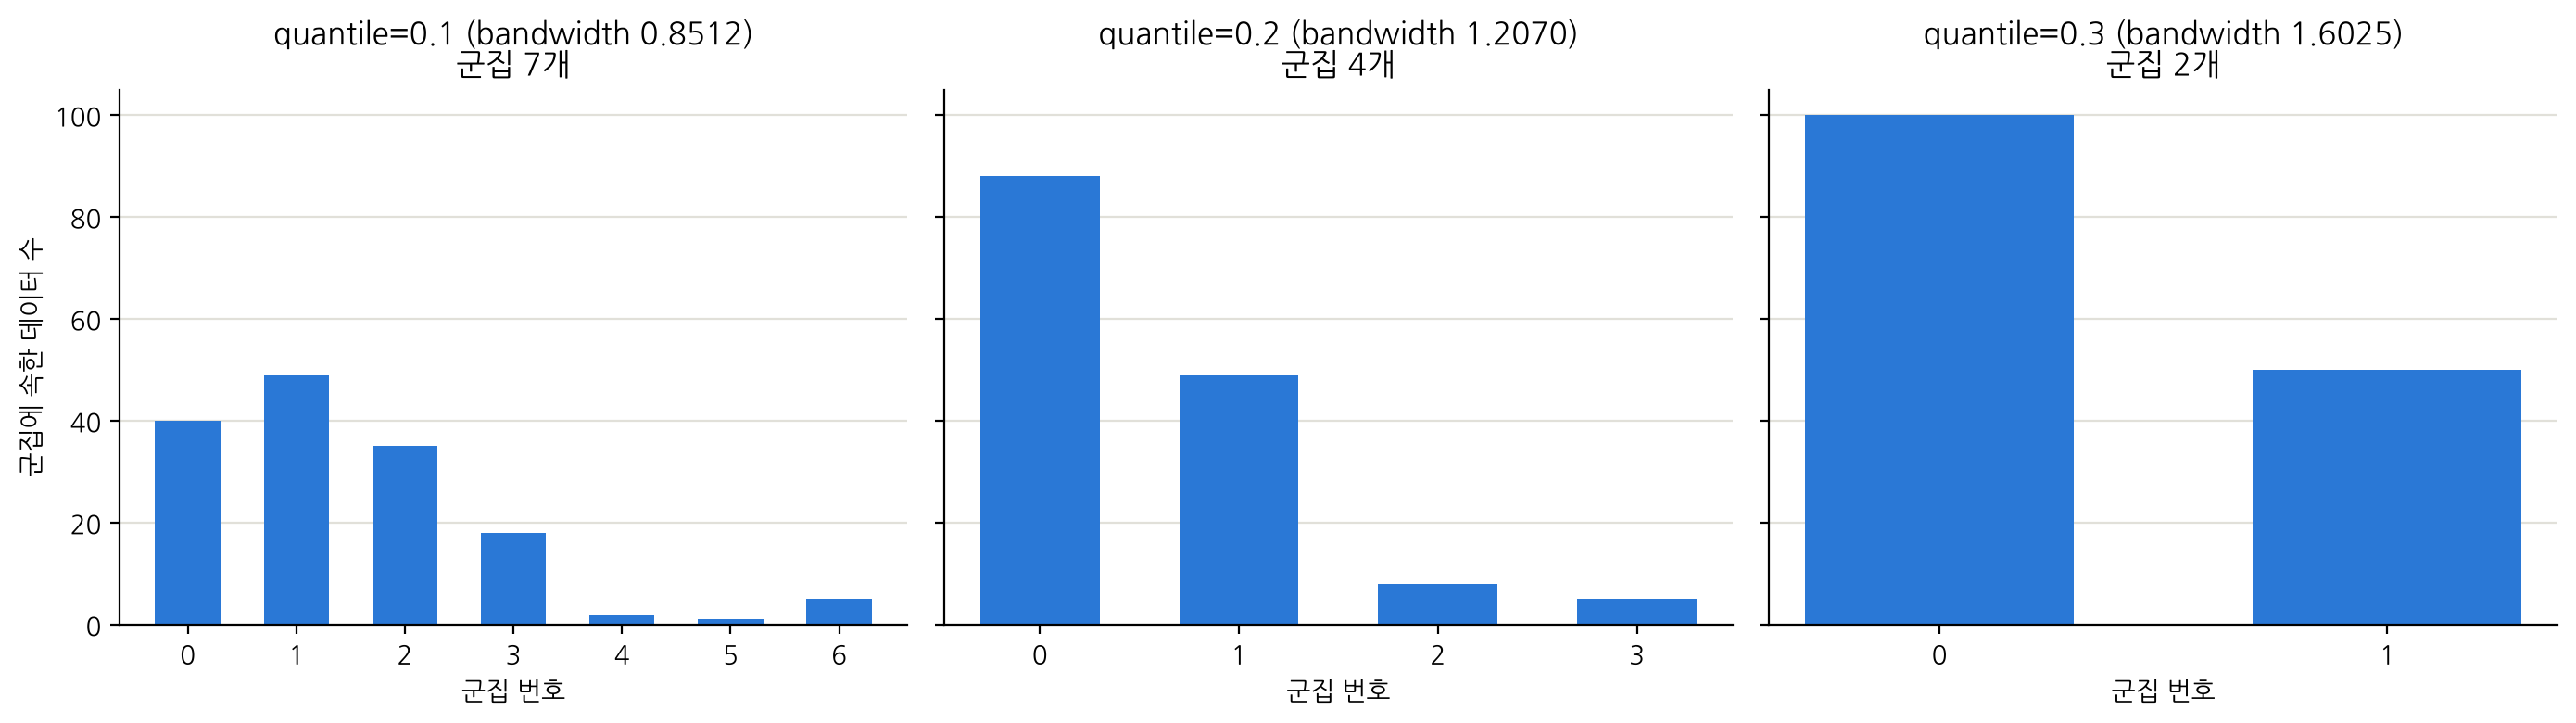

In [15]:
# 군집별 크기를 막대그래프로 나란히 비교 (작은 그래프 3개 = 같은 기준으로 비교하는 '스몰 멀티플')
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)  # 1행 3열, y축 눈금 공유 → 막대 높이를 공정하게 비교
for ax, row in zip(axes, ms_results):                         # quantile 결과를 그래프 하나씩에 그리기
    sizes = row["군집별 크기"]                                  # 군집 번호별 데이터 수 리스트
    ax.bar(range(len(sizes)), sizes, color=COLORS[0], width=0.6)  # 군집별 크기를 막대로 (하나의 색으로 통일)
    ax.set(title=f"quantile={row['quantile']} (bandwidth {row['bandwidth']:.4f})\n군집 {row['군집 수']}개",  # 제목: 설정값과 군집 수
           xlabel="군집 번호", xticks=range(len(sizes)))       # 제목과 x축 눈금
    ax.grid(axis="x", visible=False)                          # 세로 격자는 숨기고 가로 격자만 남기기
axes[0].set_ylabel("군집에 속한 데이터 수")                     # 맨 왼쪽 그래프에만 y축 이름
plt.tight_layout()                                             # 간격 자동 조정
plt.show()                                                     # 출력

→ **bandwidth가 작을수록 군집이 잘게 쪼개집니다.**
- quantile 0.1(bandwidth 0.8512) → 군집 **7개**: 크기가 1~5송이뿐인 아주 작은 군집이 3개나 생겼습니다.
- quantile 0.2(bandwidth 1.2070) → **4개**, quantile 0.3(bandwidth 1.6025) → **2개**
- ARI는 quantile 0.1일 때 **0.5956**으로 가장 높지만 실루엣은 **0.3584**로 낮습니다. 반대로 quantile 0.3은 ARI 0.5681, 실루엣 **0.5818**로 실루엣이 가장 높습니다.
- 즉 **'정답과 잘 맞는가(ARI)'와 '모양상 깔끔하게 나뉘었는가(실루엣)'는 서로 다른 기준**입니다. 실제 현장에는 정답이 없으므로 실루엣 같은 내부 지표와 도메인 지식(예: 의학적으로 의미 있는 그룹인가)을 함께 보고 bandwidth를 정합니다.

### 1-5. PCA로 2차원 시각화
피처가 4개(4차원)라 그대로는 그림을 그릴 수 없습니다. 그래서 **PCA(주성분 분석, Principal Component Analysis)** 로 정보를 최대한 남기면서 2차원으로 줄여 그립니다.

🔦 **비유**: 입체 조형물에 손전등을 비춰 벽에 그림자를 만들 때, **모양이 가장 잘 드러나는 각도**를 고르는 것과 비슷합니다. 데이터가 가장 넓게 퍼진 방향을 첫 번째 축(PC1)으로, 그와 직각이면서 그다음으로 넓게 퍼진 방향을 두 번째 축(PC2)으로 삼습니다.

> ⚠️ PCA는 **그림을 그리기 위해서만** 사용합니다. 군집화는 이미 4차원 전체(`X_scaled`)로 했습니다.

In [16]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)  # 주성분(새 축) 2개로 줄이는 PCA 만들기
X_pca = pca.fit_transform(X_scaled)                   # 표준화된 4차원 데이터 → 2차원 좌표로 변환

print("주성분별 설명된 분산 비율:", pca.explained_variance_ratio_.round(4))        # 각 축이 원래 정보(분산)를 얼마나 담는지
print(f"두 축이 보존한 정보: {pca.explained_variance_ratio_.sum():.2%}")           # 합계 (100%에 가까울수록 원래 모양을 잘 보존)

주성분별 설명된 분산 비율: [0.7296 0.2285]
두 축이 보존한 정보: 95.81%


→ 두 축(PC1, PC2)이 원래 정보(분산)의 **95.81%** 를 담고 있어서, 2차원 그림만으로도 4차원 데이터의 구조를 꽤 믿을 만하게 볼 수 있습니다.

In [17]:
def plot_on_pca(ax, labels, title, names=None):  # ax: 그릴 위치, labels: 그룹 번호, title: 제목, names: 번호→이름 사전(선택)
    """PCA 2차원 좌표(X_pca) 위에 그룹별로 색·모양을 다르게 찍는 함수 (라벨 -1은 회색 x 노이즈로 표시)"""
    groups = [g for g in np.unique(labels) if g != -1]  # 노이즈(-1)를 뺀 그룹 번호 목록
    for i, g in enumerate(groups):                       # 그룹을 하나씩 꺼내 반복 (i: 몇 번째 그룹인지 → 색 순서)
        mask = labels == g                               # 이 그룹에 속한 점만 True
        name = names[g] if names is not None else f"군집 {g}"  # 범례 이름 (품종 이름 또는 '군집 n')
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=40, color=COLORS[i], marker=MARKERS[i],  # 이 그룹의 점을 PC1·PC2 좌표에 찍기
                   edgecolors="white", linewidths=0.6, alpha=0.85,                         # 흰 테두리, 약간 투명하게
                   label=f"{name} ({mask.sum()}개)")     # 그룹별 색·모양으로 점 찍기
    if -1 in labels:                                     # 노이즈 점이 있으면
        mask = labels == -1                              # 노이즈 점만 True
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=80, color=NOISE_COLOR, marker="x",  # 노이즈 점 찍기
                   linewidths=2, label=f"노이즈 -1 ({mask.sum()}개)")  # 회색 x로 표시
    ax.set(title=title, xlabel="주성분 1 (PC1)", ylabel="주성분 2 (PC2)")  # 제목·축 이름
    ax.legend(fontsize=9)                                 # 범례 표시


species_dict = dict(enumerate(iris.target_names.tolist()))  # {0: 'setosa', 1: 'versicolor', 2: 'virginica'} 번호 → 이름 사전 (tolist: 일반 파이썬 문자열로)
print(species_dict)                                       # 사전 내용 확인

{0: 'setosa', 1: 'versicolor', 2: 'virginica'}


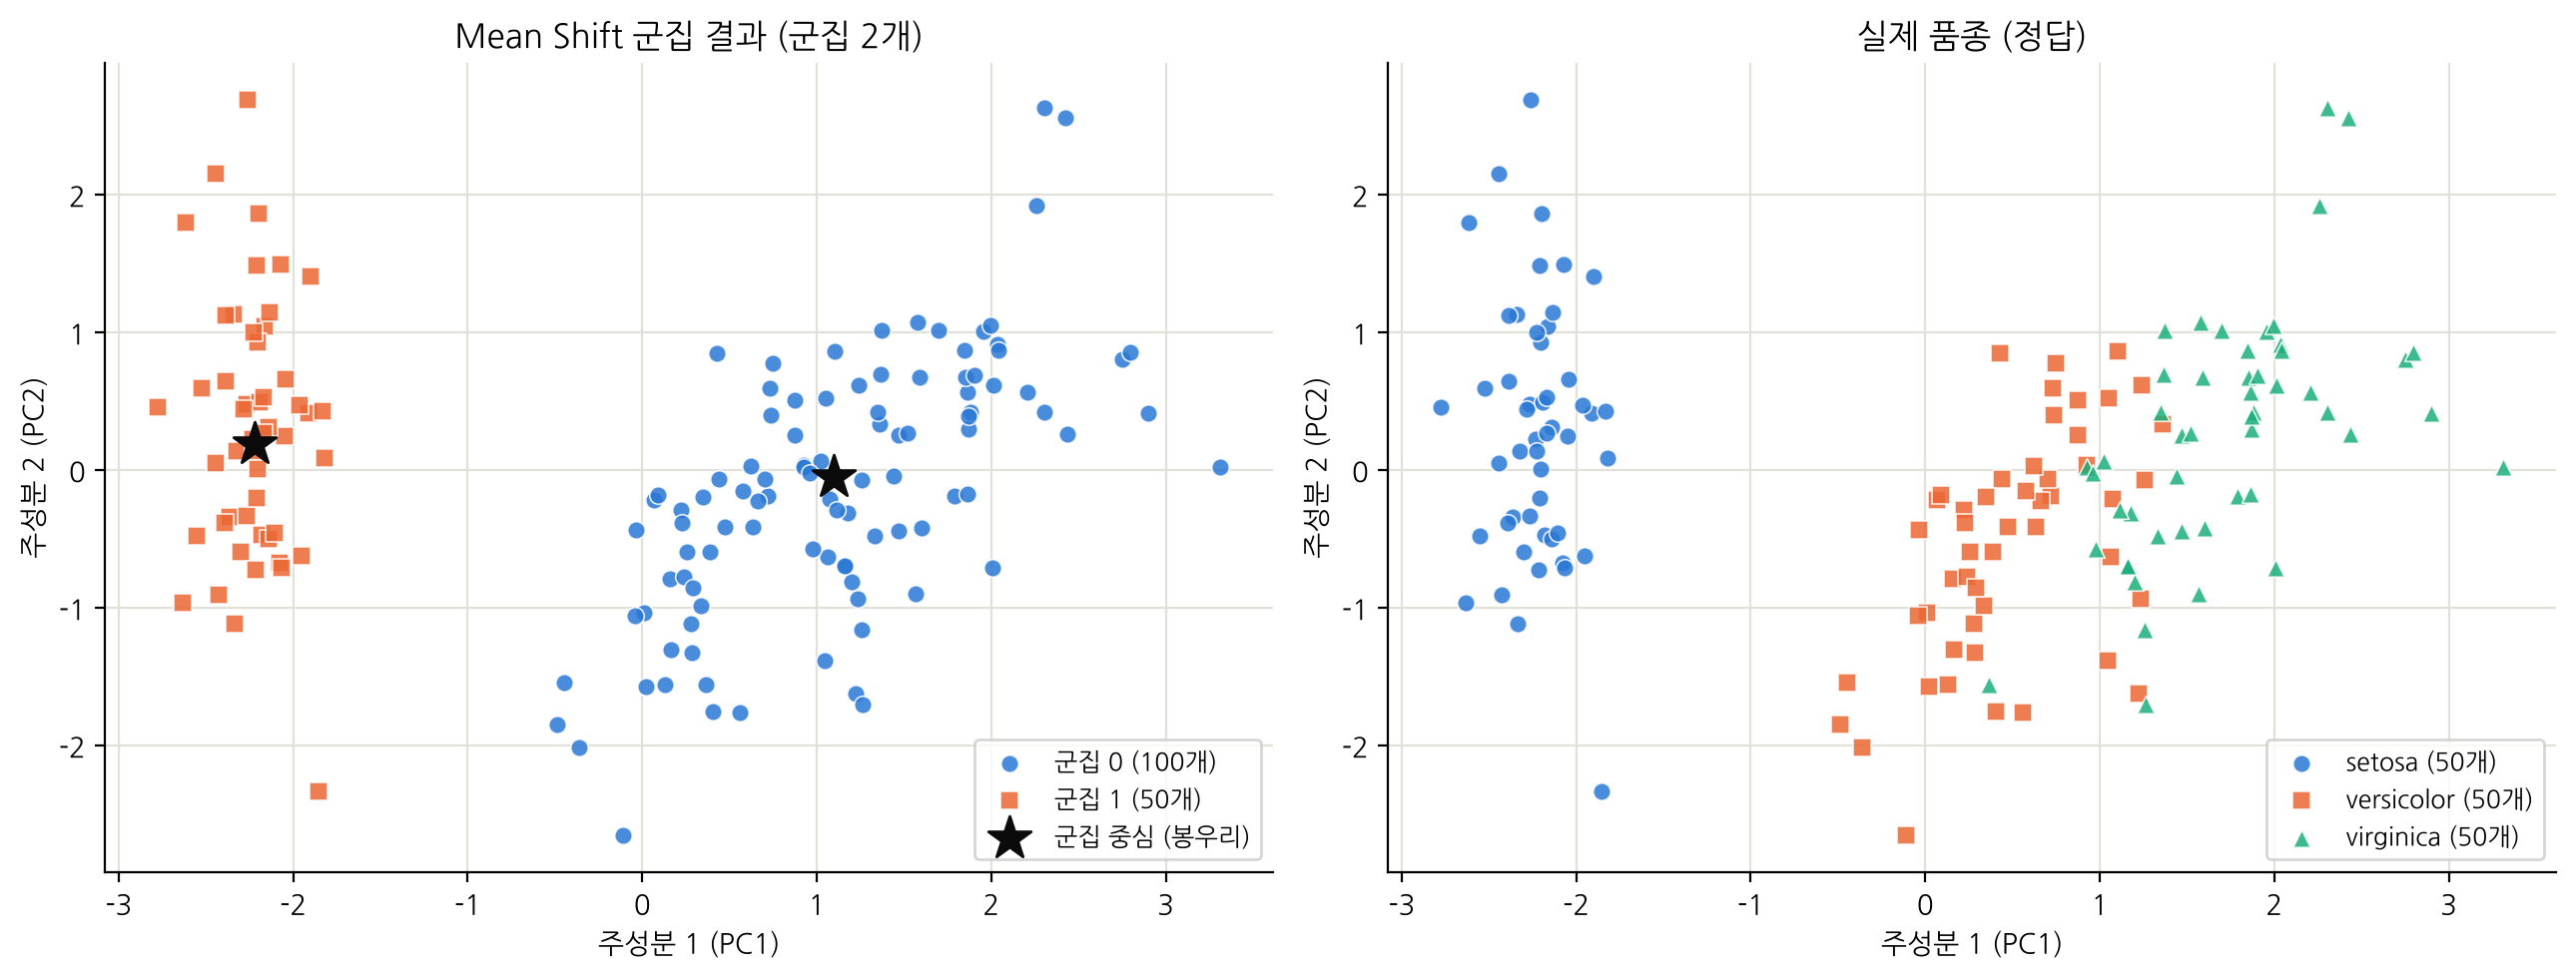

In [18]:
centers_pca = pca.transform(meanshift.cluster_centers_)  # 군집 중심(봉우리)도 같은 PCA 축 위의 좌표로 변환

fig, axes = plt.subplots(1, 2, figsize=(13, 5))                                    # 1행 2열
plot_on_pca(axes[0], ms_labels, f"Mean Shift 군집 결과 (군집 {n_clusters_ms}개)")   # 왼쪽: Mean Shift 결과
axes[0].scatter(centers_pca[:, 0], centers_pca[:, 1], s=260, color="#0b0b0b",       # 군집 중심 좌표에
                marker="*", label="군집 중심 (봉우리)")                               # 군집 중심을 검은 별로 표시
axes[0].legend(fontsize=9)                                                         # 군집 중심까지 넣어 범례 다시 그리기
plot_on_pca(axes[1], y_true, "실제 품종 (정답)", names=species_dict)                # 오른쪽: 실제 품종
plt.tight_layout()                                                                 # 간격 자동 조정
plt.show()                                                                         # 출력

→ 왼쪽 그래프(Mean Shift)는 **setosa 덩어리와 나머지 큰 덩어리, 2개**로 나뉘었습니다. 오른쪽(정답)과 비교하면 versicolor와 virginica가 하나로 합쳐졌다는 것이 한눈에 보입니다.
> 왼쪽과 오른쪽의 색은 서로 대응하지 않습니다. 군집 번호는 알고리즘이 임의로 붙인 이름표라서, **어떤 점들이 함께 묶였는지**만 비교하면 됩니다.

## PART 2. DBSCAN

DBSCAN(Density-Based Spatial Clustering of Applications with Noise, 밀도 기반 군집화)은 **"사람이 붐비는 곳"을 이어 붙여** 군집을 만드는 알고리즘입니다.

🏟️ **비유**: 광장에 사람들이 서 있습니다. **내 주변 반경 `eps` 안에 (나를 포함해) `min_samples`명 이상**이 있으면, 나는 붐비는 곳의 중심인 **핵심 포인트**입니다. 핵심 포인트끼리 반경 안에서 손을 잡고 이어지면 하나의 군집이 됩니다.

| 종류 | 조건 | 결과 |
|---|---|---|
| 핵심 포인트 (core point) | 반경 eps 안에 min_samples개 이상 (자기 포함) | 군집의 뼈대 |
| 경계 포인트 (border point) | 핵심 포인트는 아니지만, 어떤 핵심 포인트의 반경 안에 있음 | 그 군집에 포함 |
| 노이즈 (noise) | 어느 핵심 포인트의 반경에도 들지 못한 외톨이 | 라벨 **-1** |

Mean Shift(기본 설정)는 모든 점을 어떤 군집에든 배정하지만, DBSCAN은 **외톨이를 노이즈로 따로 빼 둔다**는 점이 큰 차이입니다.

### 2-1. min_samples 정하기
흔히 쓰는 경험칙(rule of thumb)인 **min_samples = 2 × 피처 수**를 따릅니다. 피처가 4개이므로 8입니다. (최소한 '피처 수 + 1' 이상으로 잡고, 노이즈가 많거나 데이터가 클수록 더 크게 잡는 편입니다.)

In [19]:
min_samples = 2 * X_scaled.shape[1]  # 경험칙: 2 × 피처 수 (shape[1] = 열 개수 = 4)
print("min_samples =", min_samples)  # 결과 확인

min_samples = 8


### 2-2. k-거리 그래프로 eps 정하기
`eps`는 "얼마나 가까워야 이웃인가"를 정하는 반경입니다. 감으로 정하지 않고 **k-거리 그래프(k-distance plot)** 로 근거를 만듭니다.
1. 모든 점에 대해 **k번째로 가까운 이웃까지의 거리**(k-거리)를 구합니다. (k = min_samples)
2. 그 거리를 작은 순서로 정렬해 선 그래프로 그립니다.
3. 대부분의 점은 거리가 완만하게 늘다가 외톨이 점들에서 **급격히 치솟습니다.** 이 꺾이는 지점(무릎, knee)의 거리를 eps로 쓰면, 그보다 먼 외톨이들이 노이즈로 분리됩니다.

> 🔍 `NearestNeighbors`로 학습에 쓴 데이터 자신을 조회하면 **첫 번째 이웃은 자기 자신(거리 0)** 입니다. 그래서 `n_neighbors=min_samples`로 구한 마지막 열은 "자기 포함 min_samples번째 점까지의 거리"가 되고, **이 값이 eps 이하인 점이 바로 DBSCAN의 핵심 포인트**입니다. sklearn DBSCAN의 `min_samples`도 자기 자신을 포함해서 세기 때문에 정확히 맞아떨어집니다. (아래 2-3에서 직접 확인합니다.)

In [20]:
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)  # 가까운 이웃 8개(자기 포함)를 찾는 도구
distances, _ = nn.kneighbors(X_scaled)                        # 각 점에서 가까운 8개 점까지의 거리 (첫 칸은 자기 자신 = 0)
k_dist_each = distances[:, -1]                                # 각 점의 '자기 포함 8번째 점까지 거리' (정렬 전, 2-3에서 다시 사용)
k_distances = np.sort(k_dist_each)                            # 작은 순서로 정렬 → 그래프용

# 무릎(가장 크게 꺾이는 점) 자동으로 찾기
# 가로축(순번)과 세로축(거리)을 0~1로 줄인 뒤, 왼쪽 아래(0,0)와 오른쪽 위(1,1)를 잇는 대각선에서
# 가장 멀리 '아래로 처진' 점을 고릅니다. 곡선이 대각선에서 가장 많이 벗어난 곳 = 가장 크게 꺾이는 곳입니다.
x_norm = np.arange(len(k_distances)) / (len(k_distances) - 1)                          # 순번을 0~1로 변환
y_norm = (k_distances - k_distances.min()) / (k_distances.max() - k_distances.min())  # 거리를 0~1로 변환
knee_idx = int(np.argmax(x_norm - y_norm))                                              # 대각선(y=x)보다 가장 아래에 있는 점의 위치
eps = round(float(k_distances[knee_idx]), 2)                                            # 그 점의 거리를 소수 둘째 자리로 반올림해 eps로 사용

print(f"무릎 지점: 정렬 순번 {knee_idx} (0부터 셈), 거리 = {k_distances[knee_idx]:.4f}")  # 무릎 위치와 거리 출력
print(f"→ 선택한 eps = {eps}")                                                             # 최종 eps 출력

무릎 지점: 정렬 순번 134 (0부터 셈), 거리 = 0.9483
→ 선택한 eps = 0.95


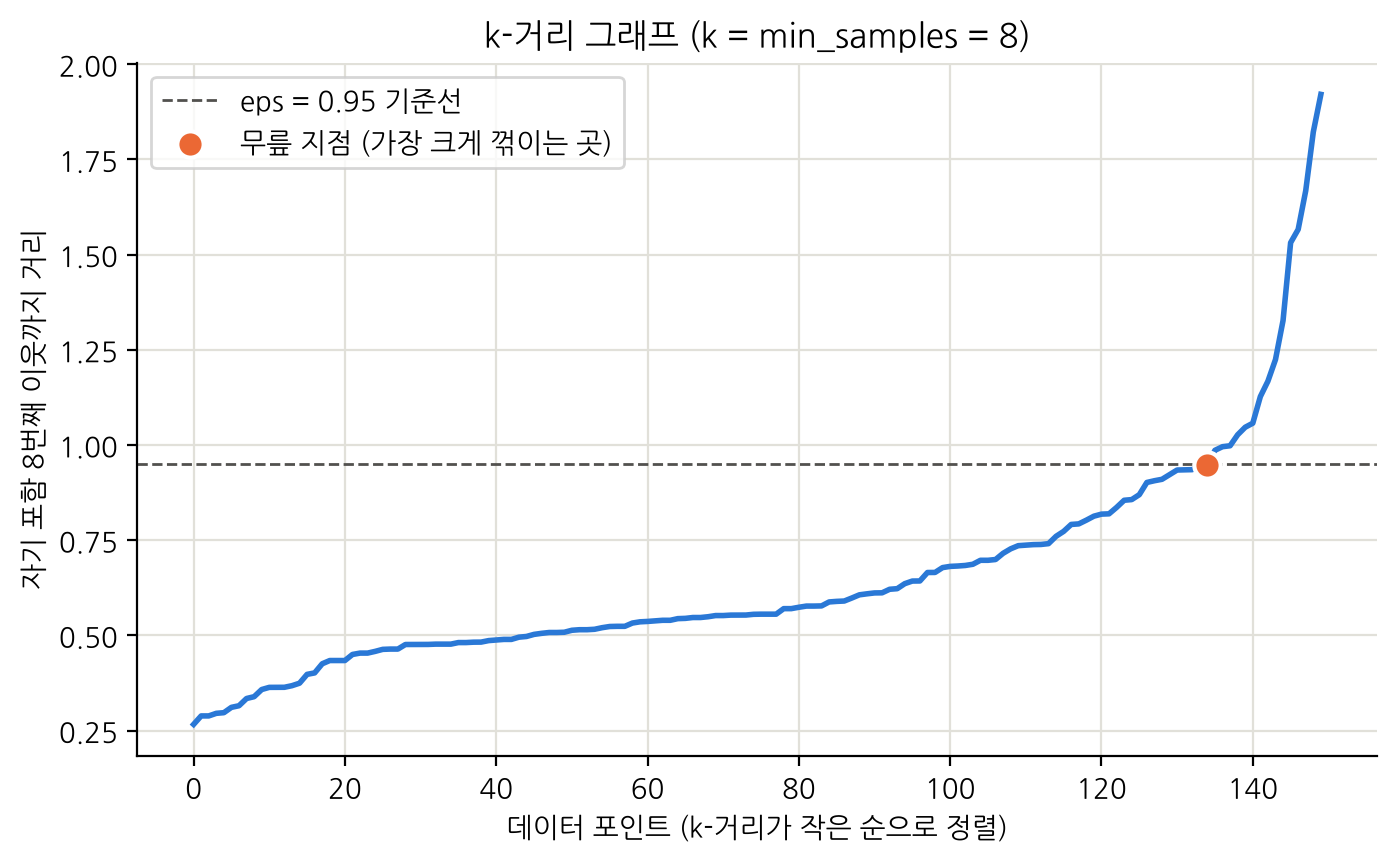

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.5))                                    # 그래프 영역 만들기
ax.plot(k_distances, color=COLORS[0], linewidth=2)                          # 정렬된 k-거리 곡선
ax.axhline(eps, color="#52514e", linestyle="--", linewidth=1, label=f"eps = {eps} 기준선")  # 선택한 eps 기준선 (점선 = 기준값 표시)
ax.scatter(knee_idx, k_distances[knee_idx], color=COLORS[1], s=90,          # 무릎 지점을 주황 점으로
           edgecolors="white", linewidths=1.5, zorder=3, label="무릎 지점 (가장 크게 꺾이는 곳)")  # 무릎 지점 강조
ax.set(title=f"k-거리 그래프 (k = min_samples = {min_samples})",               # 제목
       xlabel="데이터 포인트 (k-거리가 작은 순으로 정렬)",                          # x축 이름
       ylabel=f"자기 포함 {min_samples}번째 이웃까지 거리")                     # 제목·축 이름
ax.legend()                                                                 # 범례
plt.show()                                                                  # 출력

→ 곡선이 완만하게 오르다가 오른쪽 끝에서 급격히 치솟습니다. 자동으로 찾은 무릎 지점의 거리는 **0.9483**이고, 이를 반올림해 **eps = 0.95**를 사용합니다.

### 2-3. DBSCAN 학습하기

In [22]:
dbscan = DBSCAN(eps=eps, min_samples=min_samples)  # 정한 eps, min_samples로 DBSCAN 모델 만들기
db_labels = dbscan.fit_predict(X_scaled)           # 학습 + 각 점의 군집 번호 받기 (노이즈는 -1)

n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)  # 군집 수 (노이즈 라벨 -1은 군집이 아니므로 빼기)
n_noise_db = int((db_labels == -1).sum())                            # 노이즈 점 개수
n_core = len(dbscan.core_sample_indices_)                            # 핵심 포인트 개수
n_border = len(X_scaled) - n_core - n_noise_db                       # 경계 포인트 = 전체 − 핵심 − 노이즈

print(f"DBSCAN 군집 수: {n_clusters_db}개")                                       # 군집 수 출력
print(f"노이즈(-1) 수: {n_noise_db}개")                                           # 노이즈 수 출력
print(f"핵심 포인트 {n_core}개 / 경계 포인트 {n_border}개 / 노이즈 {n_noise_db}개")  # 점 종류별 개수 출력
print("\n군집별 데이터 수 (-1 = 노이즈):")                                         # 소제목 출력
print(pd.Series(db_labels, name="군집").value_counts().sort_index())  # 번호 순으로 개수 출력

# 🔍 2-2의 설명 확인: 'k-거리 ≤ eps'인 점의 수 = 핵심 포인트 수
print("\nk-거리 ≤ eps 인 점의 수:", int((k_dist_each <= eps).sum()), "/ 핵심 포인트 수:", n_core)  # 두 숫자가 같으면 설명이 맞음

DBSCAN 군집 수: 2개
노이즈(-1) 수: 4개
핵심 포인트 135개 / 경계 포인트 11개 / 노이즈 4개

군집별 데이터 수 (-1 = 노이즈):
군집
-1     4
 0    48
 1    98
Name: count, dtype: int64

k-거리 ≤ eps 인 점의 수: 135 / 핵심 포인트 수: 135


In [23]:
display(pd.crosstab(species_names, pd.Series(db_labels, name="DBSCAN 군집")))  # 품종 × 군집 교차표 (-1 = 노이즈)

not_noise = db_labels != -1                                                # 노이즈가 아닌 점만 True
db_ari = adjusted_rand_score(y_true, db_labels)                            # 전체 150개 기준 ARI (노이즈 -1도 하나의 묶음으로 계산됨)
db_ari_no_noise = adjusted_rand_score(y_true[not_noise], db_labels[not_noise])  # 노이즈를 뺀 점들만으로 계산한 ARI (참고용)
db_sil = silhouette_score(X_scaled[not_noise], db_labels[not_noise])       # 실루엣은 노이즈를 빼고 계산 (노이즈는 군집이 아니므로)

print(f"ARI (전체 150개): {db_ari:.4f}")                                    # 전체 기준 ARI
print(f"ARI (노이즈 제외 {not_noise.sum()}개, 참고): {db_ari_no_noise:.4f}")  # 노이즈 제외 ARI
print(f"실루엣 점수 (노이즈 제외): {db_sil:.4f}")                             # 노이즈 제외 실루엣

DBSCAN 군집,-1,0,1
실제 품종,,,
setosa,2,48,0
versicolor,0,0,50
virginica,2,0,48


ARI (전체 150개): 0.5438
ARI (노이즈 제외 146개, 참고): 0.5632
실루엣 점수 (노이즈 제외): 0.5967


→ DBSCAN도 **군집 2개 + 노이즈 4개**를 찾았습니다.
- 교차표: setosa 48송이가 0번 군집, versicolor 50송이와 virginica 48송이가 1번 군집으로 묶였고, **setosa 2송이와 virginica 2송이가 노이즈(-1)** 로 분리되었습니다.
- 150송이 중 핵심 포인트 135개, 경계 포인트 11개, 노이즈 4개이고, 'k-거리 ≤ eps'인 점의 수도 135개로 핵심 포인트 수와 정확히 같습니다.
- ARI는 **0.5438**(노이즈를 빼고 계산하면 0.5632), 실루엣 점수(노이즈 제외)는 **0.5967**입니다. 노이즈 4개가 '-1'이라는 별도 묶음으로 계산되기 때문에 전체 기준 ARI는 Mean Shift(0.5681)보다 조금 낮습니다.
- Mean Shift와 마찬가지로 versicolor와 virginica는 하나의 밀도 덩어리로 이어져 있어 나뉘지 않았습니다.

### 2-4. eps 바꿔 보기
`min_samples=8`은 그대로 두고 eps만 바꿔서 군집 수·노이즈 수·ARI가 어떻게 변하는지 봅니다.

In [24]:
eps_list = sorted({0.4, 0.5, 0.6, 0.7, 0.8, 1.0, 1.2, 1.5, 2.0, eps})  # eps 후보들 (위에서 선택한 eps도 포함, 중복 제거 후 정렬)
db_results = []                                                        # 결과를 한 줄씩 담을 리스트
for e in eps_list:                                                     # eps를 하나씩 바꿔 가며 반복
    labels = DBSCAN(eps=e, min_samples=min_samples).fit_predict(X_scaled)  # 해당 eps로 군집화
    n_clu = len(set(labels)) - (1 if -1 in labels else 0)              # 군집 수 (노이즈 제외)
    mask = labels != -1                                                # 노이즈가 아닌 점
    sil = silhouette_score(X_scaled[mask], labels[mask]) if n_clu >= 2 else np.nan  # 군집이 2개 이상일 때만 실루엣 계산
    db_results.append({                                                # 결과 한 줄을 딕셔너리로 추가
        "eps": e,                                                      # 사용한 eps
        "군집 수": n_clu,                                               # 찾은 군집 수
        "노이즈 수": int((labels == -1).sum()),                          # 노이즈(-1) 개수
        "ARI": round(adjusted_rand_score(y_true, labels), 4),          # 정답과의 일치도 (전체 150개 기준)
        "실루엣(노이즈 제외)": round(sil, 4),                             # 군집 품질 (군집 1개면 NaN)
    })
db_table = pd.DataFrame(db_results)  # 표로 변환
db_table                             # 표 출력

,eps,군집 수,노이즈 수,ARI,실루엣(노이즈 제외)
0,0.40,2,117,0.1742,0.5029
1,0.50,3,59,0.4436,0.6029
2,0.60,2,32,0.4470,0.6484
3,0.70,2,17,0.5008,0.6267
4,0.80,2,8,0.5344,0.6083
5,0.95,2,4,0.5438,0.5967
6,1.00,2,3,0.5536,0.5952
7,1.20,2,3,0.5536,0.5952
8,1.50,2,0,0.5681,0.5818
9,2.00,1,0,0.0000,NaN


→ **DBSCAN은 eps에 매우 민감합니다.**
- eps가 작으면 **노이즈가 폭증**합니다. eps 0.4에서는 150송이 중 117송이가 노이즈입니다.
- eps 0.5에서는 군집이 3개로 나오지만 노이즈가 59개나 되어, 품종 3개를 제대로 찾았다고 보기 어렵습니다.
- eps를 키울수록 노이즈가 줄어 eps 1.5에서는 노이즈 0개가 되고, Mean Shift와 같은 ARI(0.5681)가 나옵니다.
- eps 2.0에서는 모든 점이 **1개 군집으로 합쳐져** ARI가 0이 되고, 군집이 1개라 실루엣은 계산할 수 없습니다(NaN).
- 그래서 eps는 k-거리 그래프 같은 **근거**를 가지고 정하는 것이 중요합니다.

### 2-5. PCA로 2차원 시각화 (노이즈 표시)

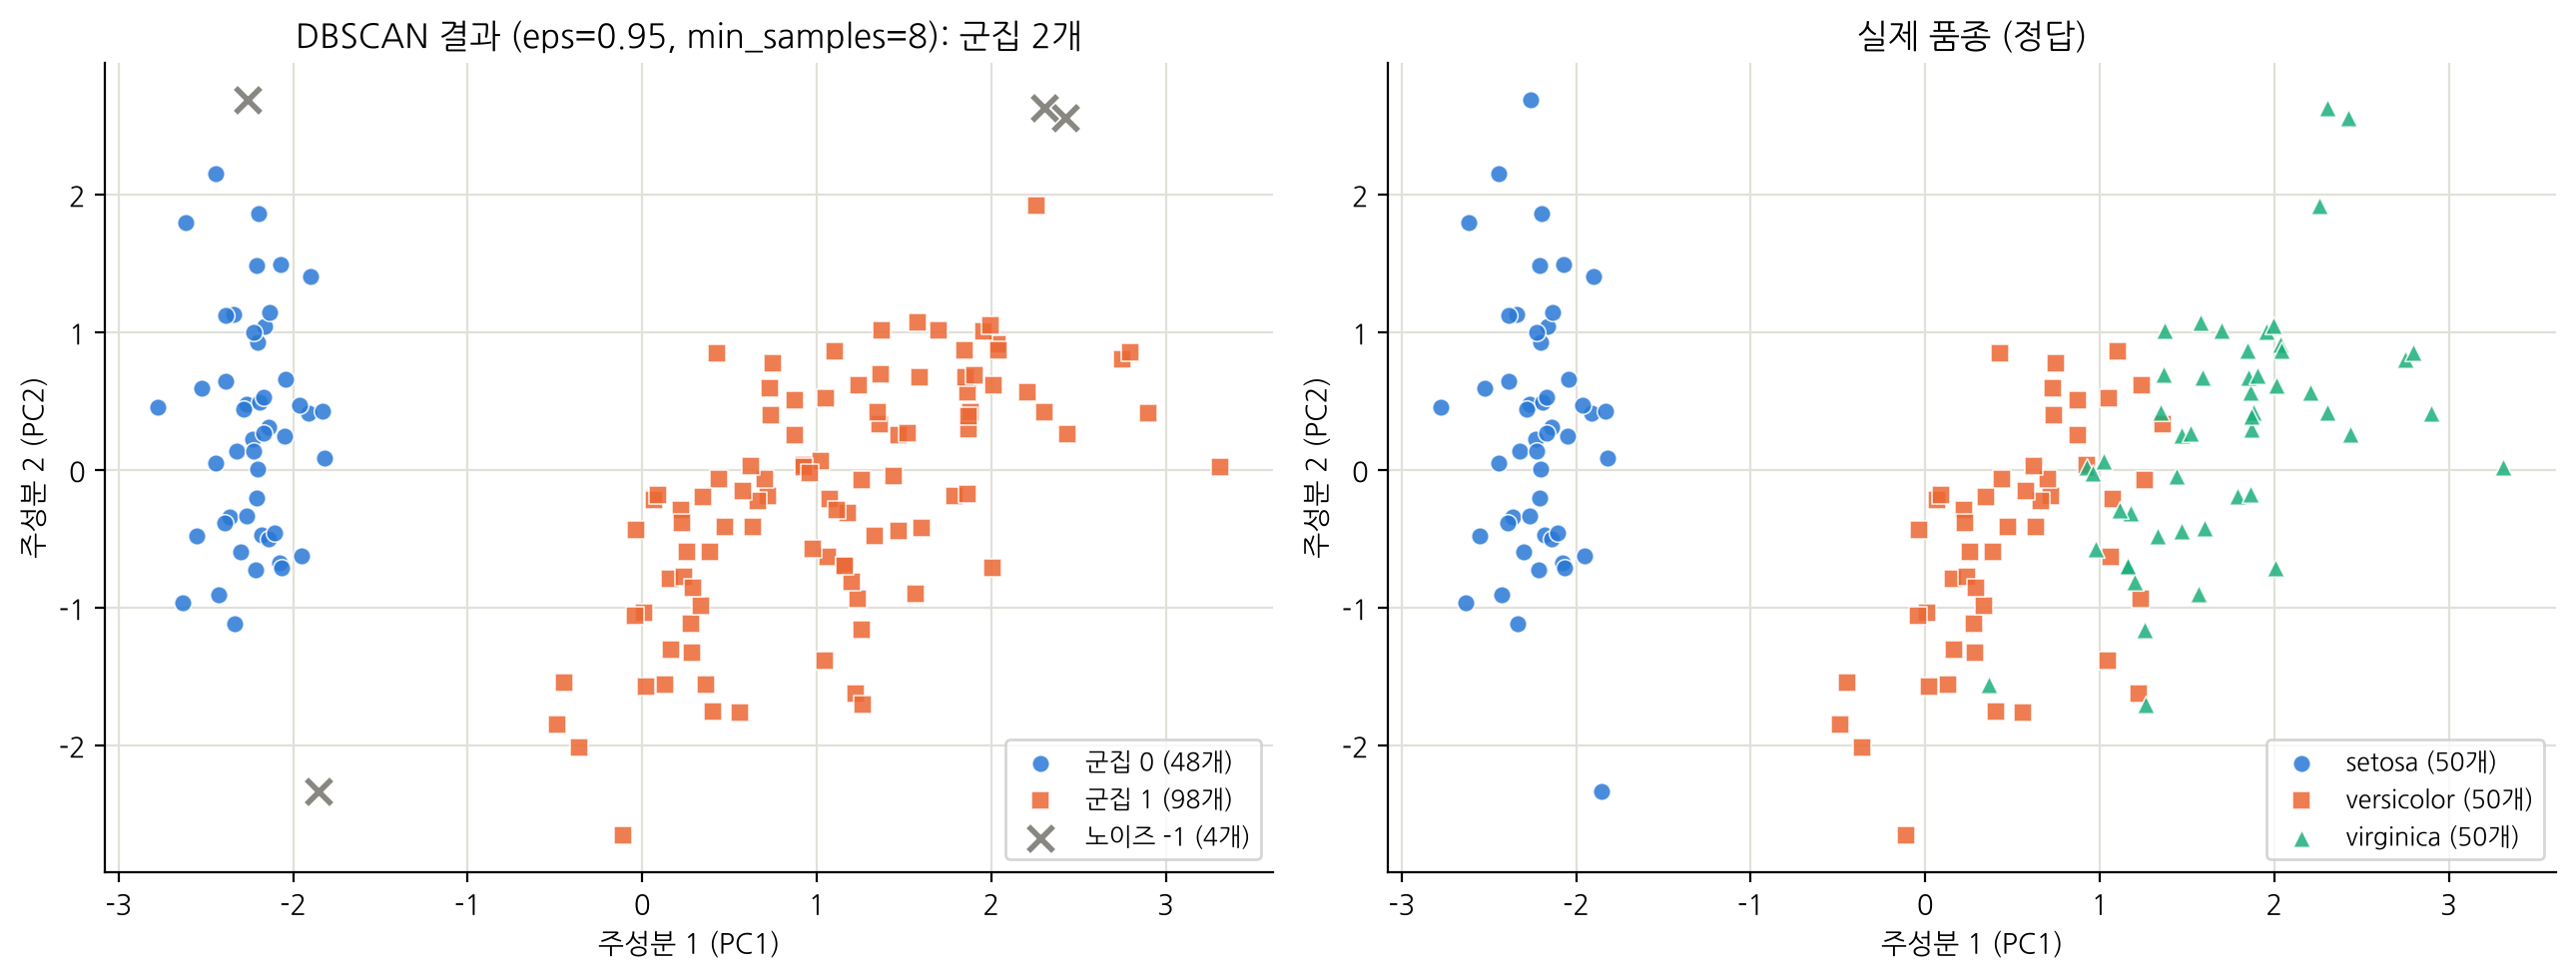

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))                                          # 1행 2열
plot_on_pca(axes[0], db_labels,                                                          # 왼쪽 그래프에 DBSCAN 라벨로 그리기
            f"DBSCAN 결과 (eps={eps}, min_samples={min_samples}): 군집 {n_clusters_db}개")  # 왼쪽: DBSCAN 결과 (노이즈는 회색 x)
plot_on_pca(axes[1], y_true, "실제 품종 (정답)", names=species_dict)                      # 오른쪽: 실제 품종
plt.tight_layout()                                                                       # 간격 자동 조정
plt.show()                                                                               # 출력

→ 회색 ×로 표시된 **노이즈 4개는 모두 각 덩어리에서 멀찍이 떨어진 가장자리 점**들입니다(setosa 쪽 2개, virginica 쪽 2개). 나머지는 Mean Shift와 마찬가지로 setosa 덩어리와 versicolor+virginica 덩어리, 2개로 나뉘었습니다. 4차원에서 이웃이 부족했던 외톨이 점들이 2차원 그림에서도 바깥쪽에 보이는 것을 확인할 수 있습니다.

## PART 3. Mean Shift vs DBSCAN 비교 정리

In [26]:
summary = pd.DataFrame(                                                     # 두 알고리즘의 최종 결과를 한 표로
    {                                                                       # 열 이름: [Mean Shift 값, DBSCAN 값]
        "주요 파라미터": [f"bandwidth={bandwidth:.4f} (quantile=0.3)", f"eps={eps}, min_samples={min_samples}"],  # 사용한 설정
        "군집 수": [n_clusters_ms, n_clusters_db],                           # 찾은 군집 수
        "노이즈 수": [int((ms_labels == -1).sum()), n_noise_db],             # Mean Shift는 기본 설정에서 노이즈 없음
        "ARI": [ms_ari, db_ari],                                             # 정답과의 일치도
        "실루엣 (DBSCAN은 노이즈 제외)": [ms_sil, db_sil],                    # 군집 품질
    },
    index=["Mean Shift", "DBSCAN"],                                          # 행 이름
)
summary                                                                      # 표 출력

,주요 파라미터,군집 수,노이즈 수,ARI,실루엣 (DBSCAN은 노이즈 제외)
Mean Shift,bandwidth=1.6025 (quantile=0.3),2,0,0.5681,0.5818
DBSCAN,"eps=0.95, min_samples=8",2,4,0.5438,0.5967


| 비교 항목 | Mean Shift | DBSCAN |
|---|---|---|
| 핵심 아이디어 | 밀도의 **봉우리(mode)** 를 찾아 올라감 | **밀도가 이어진 영역**을 하나로 연결 |
| 군집 수 자동 결정 | ✅ 미리 정하지 않음 (bandwidth가 간접적으로 결정) | ✅ 미리 정하지 않음 (eps·min_samples가 간접적으로 결정) |
| 밀도 기반 / 노이즈 처리 | 기본 설정(`cluster_all=True`)은 **모든 점을 군집에 배정** → 노이즈 0개 | 외톨이를 **노이즈(-1)로 분리** → 노이즈 4개 |
| 파라미터 | bandwidth 1개 (`estimate_bandwidth`로 추정) | eps, min_samples 2개 (k-거리 그래프 + 경험칙) |
| 이번 결과 | bandwidth 1.6025 → 군집 2개, ARI 0.5681, 실루엣 0.5818 | eps 0.95, min_samples 8 → 군집 2개 + 노이즈 4개, ARI 0.5438, 실루엣(노이즈 제외) 0.5967 |
| 파라미터 민감도 | quantile 0.1 / 0.2 / 0.3 → 군집 7 / 4 / 2개 | eps 0.4 → 노이즈 117개, eps 2.0 → 1개로 합쳐짐 |

### 💡 배운 점
1. **두 알고리즘 모두 3품종이 아니라 2개 군집을 찾았습니다.** setosa는 확실히 떨어져 있지만 versicolor와 virginica 사이에는 밀도가 낮은 '골짜기'가 뚜렷하지 않아서, 밀도 기반 방법으로는 하나의 덩어리로 보입니다. 군집화는 사람이 붙인 이름(품종)이 아니라 **데이터의 생김새**만 보고 묶는다는 점을 확인했습니다.
2. **파라미터가 결과를 좌우합니다.** Mean Shift는 bandwidth가 작을수록 군집이 잘게 쪼개지고, DBSCAN은 eps가 작으면 노이즈가 폭증하고 크면 모두 하나로 합쳐집니다. 그래서 `estimate_bandwidth`, k-거리 그래프처럼 **근거 있는 방법으로 파라미터를 정하는 과정**이 중요합니다.
3. **평가 지표는 목적에 맞게 봐야 합니다.** ARI는 '정답과의 일치도', 실루엣은 '모양상 깔끔함'입니다. Mean Shift quantile 0.1은 ARI가 가장 높았지만(0.5956) 자잘한 군집이 생기면서 실루엣은 낮았습니다(0.3584).
4. **노이즈를 따로 볼 수 있다는 것이 DBSCAN의 장점**입니다. 의료 데이터라면 노이즈로 분리된 점이 측정 오류이거나 드문 사례일 수 있어 따로 확인해 볼 가치가 있습니다.

### 📚 다음에 공부하면 좋을 것
- 군집 수를 직접 3개로 지정하는 **K-Means**나 **가우시안 혼합 모델(GMM)** 로 versicolor와 virginica를 나눌 수 있는지 비교해 보기
- 밀도가 서로 다른 군집도 잘 잡는 **HDBSCAN** (scikit-learn 1.3부터 `sklearn.cluster.HDBSCAN`으로 제공)